In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("INvideos.csv", encoding="utf-8")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (37352, 16)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,kzwfHumJyYc,17.14.11,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12T12:20:39.000Z,"sharry mann|""sharry mann new song""|""sharry man...",1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,False,False,False,Presenting Sharry Mann latest Punjabi Song Cu...
1,zUZ1z7FwLc8,17.14.11,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",HJ NEWS,25,2017-11-13T05:43:56.000Z,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,True,False,False,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं..."
2,10L1hZ9qa58,17.14.11,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,TFPC,24,2017-11-12T15:48:08.000Z,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,243,149,https://i.ytimg.com/vi/10L1hZ9qa58/default.jpg,False,False,False,Watch Stylish Star Allu Arjun @ ChaySam Weddin...
3,N1vE8iiEg64,17.14.11,Eruma Saani | Tamil vs English,Eruma Saani,23,2017-11-12T07:08:48.000Z,"Eruma Saani|""Tamil Comedy Videos""|""Films""|""Mov...",1242680,70353,1624,2684,https://i.ytimg.com/vi/N1vE8iiEg64/default.jpg,False,False,False,This video showcases the difference between pe...
4,kJzGH0PVQHQ,17.14.11,why Samantha became EMOTIONAL @ Samantha naga ...,Filmylooks,24,2017-11-13T01:14:16.000Z,"Filmylooks|""latest news""|""telugu movies""|""telu...",464015,492,293,66,https://i.ytimg.com/vi/kJzGH0PVQHQ/default.jpg,False,False,False,why Samantha became EMOTIONAL @ Samantha naga ...


In [ ]:

# 1. Check column names and data types
print("DATA TYPES")
df.info()

# 2. Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 4. Check numeric summary
print("\nNUMERIC SUMMARY")
display(df[["views", "likes", "dislikes", "comment_count"]].describe())


DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37352 entries, 0 to 37351
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   video_id                37352 non-null  object
 1   trending_date           37352 non-null  object
 2   title                   37352 non-null  object
 3   channel_title           37352 non-null  object
 4   category_id             37352 non-null  int64 
 5   publish_time            37352 non-null  object
 6   tags                    37352 non-null  object
 7   views                   37352 non-null  int64 
 8   likes                   37352 non-null  int64 
 9   dislikes                37352 non-null  int64 
 10  comment_count           37352 non-null  int64 
 11  thumbnail_link          37352 non-null  object
 12  comments_disabled       37352 non-null  bool  
 13  ratings_disabled        37352 non-null  bool  
 14  video_error_or_removed  37352 non-null  boo

,views,likes,dislikes,comment_count
count,3.735200e+04,3.735200e+04,3.735200e+04,37352.00000
mean,1.060478e+06,2.708272e+04,1.665082e+03,2676.99743
std,3.184932e+06,9.714510e+04,1.607617e+04,14868.31713
min,4.024000e+03,0.000000e+00,0.000000e+00,0.00000
25%,1.239155e+05,8.640000e+02,1.080000e+02,81.00000
50%,3.045860e+05,3.069000e+03,3.260000e+02,329.00000
75%,7.992912e+05,1.377425e+04,1.019250e+03,1285.00000
max,1.254322e+08,2.912710e+06,1.545017e+06,827755.00000


In [ ]:

# Preserve the original data
df_raw = df.copy()

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Convert numeric columns
numeric_cols = ["views", "likes", "dislikes", "comment_count",
                "category_id"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert dates
df["publish_time"] = pd.to_datetime(
    df["publish_time"], errors="coerce", utc=True
)

# Dataset date format is commonly YY.DD.MM
df["trending_date"] = pd.to_datetime(
    df["trending_date"], format="%y.%d.%m", errors="coerce"
)

# Remove rows without essential analysis fields
df = df.dropna(subset=["video_id", "title", "views"]).copy()

# Remove impossible negative engagement values
for col in ["views", "likes", "dislikes", "comment_count"]:
    df = df[df[col].isna() | (df[col] >= 0)]

print("Original rows:", len(df_raw))
print("Rows after cleaning:", len(df))
print("Rows removed:", len(df_raw) - len(df))
print("Remaining duplicates:", df.duplicated().sum())
print("Missing values after cleaning:")
print(df.isnull().sum())


Original rows: 37352
Rows after cleaning: 33089
Rows removed: 4263
Remaining duplicates: 0
Missing values after cleaning:
video_id                    0
trending_date               0
title                       0
channel_title               0
category_id                 0
publish_time                0
tags                        0
views                       0
likes                       0
dislikes                    0
comment_count               0
thumbnail_link              0
comments_disabled           0
ratings_disabled            0
video_error_or_removed      0
description               527
dtype: int64


In [ ]:

# Fill missing engagement counts with zero for calculations
for col in ["likes", "dislikes", "comment_count"]:
    df[col] = df[col].fillna(0)

# Calculate engagement metrics
df["engagement_rate_pct"] = np.where(
    df["views"] > 0,
    (df["likes"] + df["comment_count"]) / df["views"] * 100,
    0
)

df["like_rate_pct"] = np.where(
    df["views"] > 0,
    df["likes"] / df["views"] * 100,
    0
)

df["publish_date"] = df["publish_time"].dt.date
df["publish_hour_utc"] = df["publish_time"].dt.hour
df["trending_year"] = df["trending_date"].dt.year
df["trending_month"] = df["trending_date"].dt.month

display(df[[
    "title", "views", "likes", "comment_count",
    "engagement_rate_pct"
]].head())

print("Metrics created successfully.")


,title,views,likes,comment_count,engagement_rate_pct
0,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,1096327,33966,882,3.178614
1,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",590101,735,0,0.124555
2,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,149,0.455708
3,Eruma Saani | Tamil vs English,1242680,70353,2684,5.877378
4,why Samantha became EMOTIONAL @ Samantha naga ...,464015,492,66,0.120255


Metrics created successfully.


In [ ]:

print("Dataset shape:", df.shape)
print("Unique videos:", df["video_id"].nunique())
print("Total views:", f'{df["views"].sum():,}')
print("Average views:", round(df["views"].mean(), 2))
print("Median views:", round(df["views"].median(), 2))
print("Average likes:", round(df["likes"].mean(), 2))
print("Average engagement rate (%):",
      round(df["engagement_rate_pct"].mean(), 3))



Dataset shape: (33089, 22)
Unique videos: 16307
Total views: 32,967,977,200
Average views: 996342.51
Median views: 275027.0
Average likes: 25587.62
Average engagement rate (%): 2.449


In [ ]:

top_videos = df.sort_values("views", ascending=False).head(10)

display(top_videos[[
    "title", "channel_title", "views", "likes", "comment_count"
]])


,title,channel_title,views,likes,comment_count
5408,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,125432237,2912710,807558
5119,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,113876217,2811216,787174
4936,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,100911567,2656672,682890
4477,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,89930713,2606663,347982
4236,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,87449453,2584674,341571
4013,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,84281319,2555411,339708
3823,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,80360459,2513102,335920
4743,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,75969469,2251815,827755
3639,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,74789251,2444956,330710
3456,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,66637636,2331352,316185


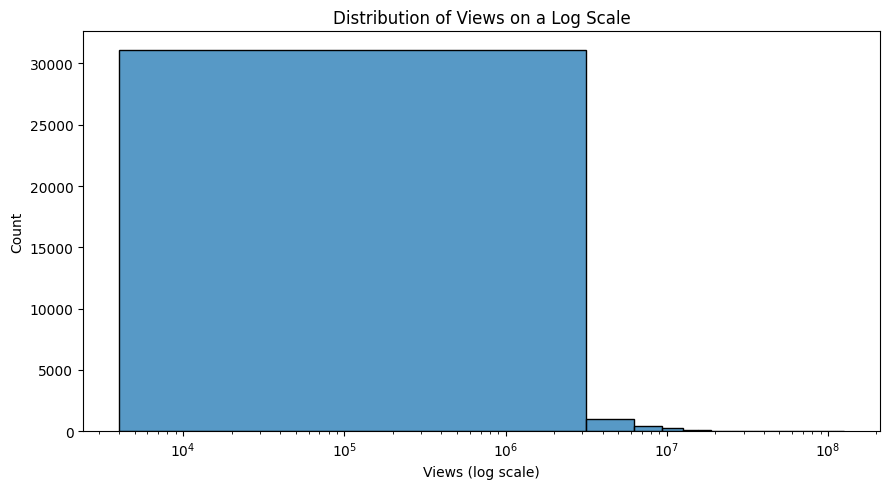

In [ ]:

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="views", bins=40)
plt.xscale("log")
plt.title("Distribution of Views on a Log Scale")
plt.xlabel("Views (log scale)")
plt.tight_layout()
plt.show()



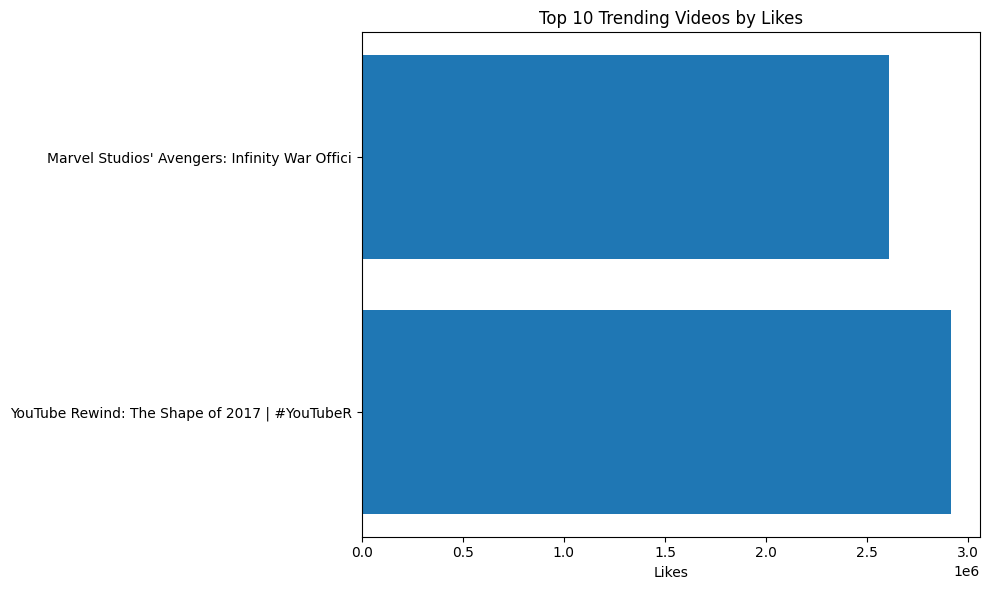

In [ ]:

top_likes = df.nlargest(10, "likes").sort_values("likes")

plt.figure(figsize=(10, 6))
plt.barh(top_likes["title"].str.slice(0, 45), top_likes["likes"])
plt.title("Top 10 Trending Videos by Likes")
plt.xlabel("Likes")
plt.tight_layout()
plt.show()


In [ ]:

category_stats = (
    df.groupby("category_id")
      .agg(
          video_records=("video_id", "count"),
          unique_videos=("video_id", "nunique"),
          avg_views=("views", "mean"),
          avg_likes=("likes", "mean"),
          avg_engagement=("engagement_rate_pct", "mean")
      )
      .reset_index()
      .sort_values("avg_views", ascending=False)
)

display(category_stats.head(10))


,category_id,video_records,unique_videos,avg_views,avg_likes,avg_engagement
6,20,55,21,3.606369e+06,92729.618182,4.293810
15,30,10,2,3.191953e+06,40975.000000,1.735499
2,10,3292,1216,2.532352e+06,64721.544046,2.770522
0,1,1463,523,2.237283e+06,39501.505810,2.140588
4,17,646,348,1.846151e+06,44077.128483,1.523497
3,15,3,2,1.626581e+06,120844.666667,6.013393
9,24,14764,7564,9.026280e+05,22231.749526,1.793064
13,28,517,302,8.428038e+05,35050.477756,10.427922
11,26,801,480,8.420285e+05,9047.575531,1.744311
8,23,2967,1117,8.168136e+05,49351.263566,5.907501


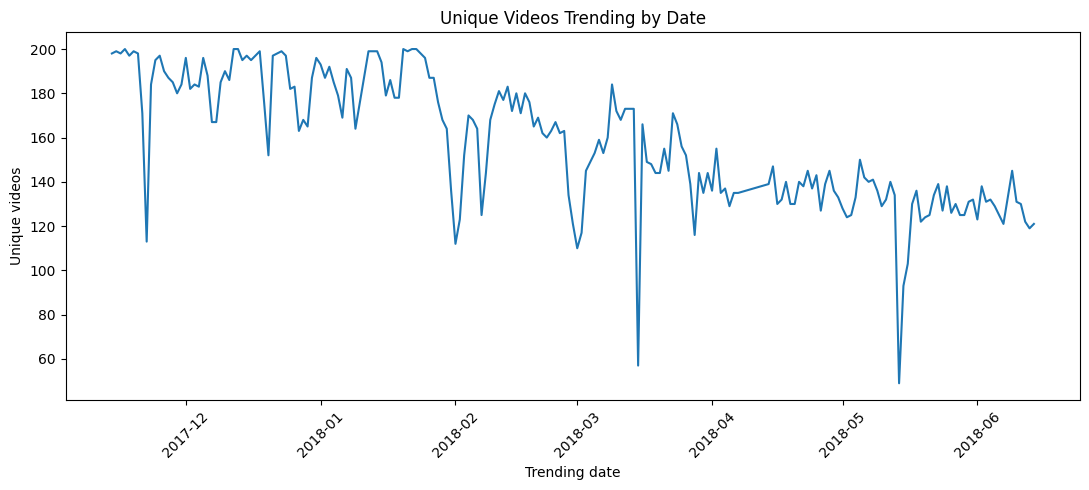

In [ ]:

daily_trending = (
    df.groupby("trending_date")["video_id"]
      .nunique()
      .reset_index(name="unique_videos")
      .dropna()
      .sort_values("trending_date")
)

plt.figure(figsize=(11, 5))
plt.plot(
    daily_trending["trending_date"],
    daily_trending["unique_videos"]
)
plt.title("Unique Videos Trending by Date")
plt.xlabel("Trending date")
plt.ylabel("Unique videos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

%pip -q install vaderSentiment


sentiment
Neutral     21976
Positive     7106
Negative     4007
Name: count, dtype: int64


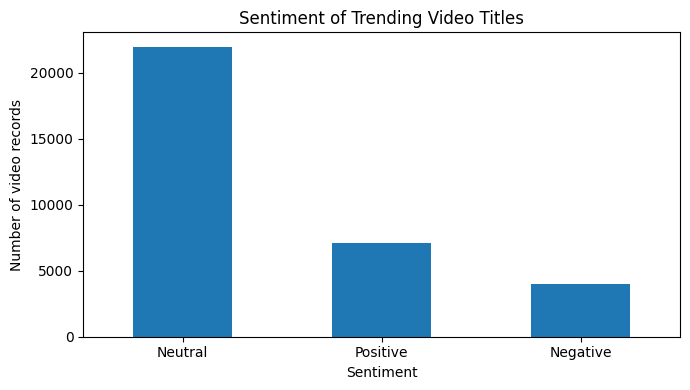

In [ ]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def get_sentiment(title):
    score = analyzer.polarity_scores(str(title))["compound"]
    if score >= 0.05:
        label = "Positive"
    elif score <= -0.05:
        label = "Negative"
    else:
        label = "Neutral"
    return pd.Series([score, label])

df[["sentiment_score", "sentiment"]] = (
    df["title"].apply(get_sentiment)
)

sentiment_counts = df["sentiment"].value_counts()
print(sentiment_counts)

sentiment_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Sentiment of Trending Video Titles")
plt.xlabel("Sentiment")
plt.ylabel("Number of video records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

display(
    df.groupby("sentiment")
      .agg(
          video_records=("video_id", "count"),
          average_views=("views", "mean"),
          average_likes=("likes", "mean"),
          average_engagement=("engagement_rate_pct", "mean")
      )
      .round(2)
)


,video_records,average_views,average_likes,average_engagement
sentiment,,,,
Negative,4007,1343720.92,37776.23,2.97
Neutral,21976,992620.39,24160.08,2.26
Positive,7106,811970.43,23129.40,2.75


In [ ]:

import sqlite3

# Create an in-memory SQL database
conn = sqlite3.connect(":memory:")

sql_df = df.copy()
sql_df.to_sql("youtube_trending", conn,
              if_exists="replace", index=False)

print("SQL table created successfully.")


SQL table created successfully.


CATEGORY RANKED BY AVERAGE VIEWS

In [ ]:

query1 = """
SELECT
    category_id,
    COUNT(*) AS video_records,
    ROUND(AVG(views), 2) AS avg_views,
    ROUND(AVG(likes), 2) AS avg_likes
FROM youtube_trending
GROUP BY category_id
HAVING COUNT(*) >= 5
ORDER BY avg_views DESC;
"""

display(pd.read_sql_query(query1, conn))


,category_id,video_records,avg_views,avg_likes
0,20,55,3606368.82,92729.62
1,30,10,3191953.00,40975.00
2,10,3292,2532352.43,64721.54
3,1,1463,2237282.93,39501.51
4,17,646,1846151.29,44077.13
5,24,14764,902627.98,22231.75
6,28,517,842803.79,35050.48
7,26,801,842028.49,9047.58
8,23,2967,816813.61,49351.26
9,43,149,664966.13,3673.32


TOP 10 CHANNELS BY TOTAL VIEWS IN THE DATASET.

In [ ]:

query2 = """
SELECT
    channel_title,
    COUNT(DISTINCT video_id) AS unique_videos,
    SUM(views) AS total_views
FROM youtube_trending
GROUP BY channel_title
ORDER BY total_views DESC
LIMIT 10;
"""

display(pd.read_sql_query(query2, conn))


,channel_title,unique_videos,total_views
0,T-Series,63,1748057724
1,Marvel Entertainment,18,1058174340
2,FoxStarHindi,7,982953616
3,Amit Bhadana,18,855533181
4,Speed Records,52,648890913
5,Goldmines Telefilms,25,592596907
6,Sony Pictures Entertainment,5,587519233
7,Zee Music Company,42,556309816
8,YRF,24,549492884
9,Dude Perfect,13,527111130


ENGAGEMENT BY SENTIMENTS

In [ ]:

query3 = """
SELECT
    sentiment,
    COUNT(*) AS video_records,
    ROUND(AVG(views), 2) AS avg_views,
    ROUND(AVG(engagement_rate_pct), 3) AS avg_engagement_pct
FROM youtube_trending
GROUP BY sentiment
ORDER BY avg_views DESC;
"""

display(pd.read_sql_query(query3, conn))


,sentiment,video_records,avg_views,avg_engagement_pct
0,Negative,4007,1343720.92,2.968
1,Neutral,21976,992620.39,2.256
2,Positive,7106,811970.43,2.754


TRENDING ACTIVITES BY DATES

In [ ]:

query4 = """
SELECT
    trending_date,
    COUNT(DISTINCT video_id) AS unique_videos
FROM youtube_trending
WHERE trending_date IS NOT NULL
GROUP BY trending_date
ORDER BY trending_date;
"""

display(pd.read_sql_query(query4, conn))


,trending_date,unique_videos
0,2017-11-14 00:00:00,198
1,2017-11-15 00:00:00,199
2,2017-11-16 00:00:00,198
3,2017-11-17 00:00:00,200
4,2017-11-18 00:00:00,197
...,...,...
200,2018-06-10 00:00:00,131
201,2018-06-11 00:00:00,130
202,2018-06-12 00:00:00,122
203,2018-06-13 00:00:00,119


In [ ]:
import os

files = [
    "CAvideos.csv", "DEvideos.csv", "FRvideos.csv",
    "GBvideos.csv", "INvideos.csv", "JPvideos.csv",
    "KRvideos.csv", "MXvideos.csv", "RUvideos.csv",
    "USvideos.csv"
]

for file in files:
    print(file, "->", "Available" if os.path.exists(file) else "Missing")

CAvideos.csv -> Available
DEvideos.csv -> Available
FRvideos.csv -> Available
GBvideos.csv -> Available
INvideos.csv -> Available
JPvideos.csv -> Available
KRvideos.csv -> Available
MXvideos.csv -> Available
RUvideos.csv -> Available
USvideos.csv -> Available


In [ ]:
import pandas as pd
import numpy as np
import os

print("Pandas version:", pd.__version__)
print("Libraries imported successfully!")

Pandas version: 2.2.3
Libraries imported successfully!


In [ ]:
import os
import pandas as pd

print("Current folder:", os.getcwd())
print("Files found:", os.listdir()[:20])
print("Pandas version:", pd.__version__)

Current folder: /content
Files found: ['.config', 'CAvideos.csv', 'USvideos.csv', 'MXvideos.csv', 'RUvideos.csv', 'KRvideos.csv', 'FRvideos.csv', 'DEvideos.csv', 'JPvideos.csv', 'GBvideos.csv', 'INvideos.csv', 'sample_data']
Pandas version: 2.2.3


In [ ]:
import pandas as pd

try:
    test_df = pd.read_csv("INvideos.csv", encoding="utf-8")
    print("File loaded successfully!")
    print("Shape:", test_df.shape)
    display(test_df.head())
except Exception as e:
    print(type(e).__name__)
    print(str(e))

File loaded successfully!
Shape: (37352, 16)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,kzwfHumJyYc,17.14.11,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12T12:20:39.000Z,"sharry mann|""sharry mann new song""|""sharry man...",1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,False,False,False,Presenting Sharry Mann latest Punjabi Song Cu...
1,zUZ1z7FwLc8,17.14.11,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",HJ NEWS,25,2017-11-13T05:43:56.000Z,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,True,False,False,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं..."
2,10L1hZ9qa58,17.14.11,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,TFPC,24,2017-11-12T15:48:08.000Z,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,243,149,https://i.ytimg.com/vi/10L1hZ9qa58/default.jpg,False,False,False,Watch Stylish Star Allu Arjun @ ChaySam Weddin...
3,N1vE8iiEg64,17.14.11,Eruma Saani | Tamil vs English,Eruma Saani,23,2017-11-12T07:08:48.000Z,"Eruma Saani|""Tamil Comedy Videos""|""Films""|""Mov...",1242680,70353,1624,2684,https://i.ytimg.com/vi/N1vE8iiEg64/default.jpg,False,False,False,This video showcases the difference between pe...
4,kJzGH0PVQHQ,17.14.11,why Samantha became EMOTIONAL @ Samantha naga ...,Filmylooks,24,2017-11-13T01:14:16.000Z,"Filmylooks|""latest news""|""telugu movies""|""telu...",464015,492,293,66,https://i.ytimg.com/vi/kJzGH0PVQHQ/default.jpg,False,False,False,why Samantha became EMOTIONAL @ Samantha naga ...


In [ ]:
import pandas as pd
import os

country_codes = ["CA", "DE", "FR", "GB", "IN",
                 "JP", "KR", "MX", "RU", "US"]

for country in country_codes:
    filename = f"{country}videos.csv"

    if os.path.exists(filename):
        try:
            test = pd.read_csv(filename, encoding="utf-8")
            print(country, "OK", test.shape)
        except Exception as e:
            print(country, "ERROR:", type(e).__name__, str(e)[:200])
    else:
        print(country, "FILE NOT FOUND")

CA OK (40881, 16)
DE OK (40840, 16)
FR OK (40724, 16)
GB OK (38916, 16)
IN OK (37352, 16)
JP ERROR: UnicodeDecodeError 'utf-8' codec can't decode bytes in position 253-254: unexpected end of data
KR ERROR: UnicodeDecodeError 'utf-8' codec can't decode bytes in position 253-254: unexpected end of data
MX ERROR: UnicodeDecodeError 'utf-8' codec can't decode byte 0xc3 in position 254: unexpected end of data
RU ERROR: UnicodeDecodeError 'utf-8' codec can't decode byte 0xd0 in position 254: unexpected end of data
US OK (40949, 16)


In [ ]:
import pandas as pd
import numpy as np
import os

country_codes = ["CA", "DE", "FR", "GB", "IN",
                 "JP", "KR", "MX", "RU", "US"]

frames = []

for country in country_codes:
    filename = f"{country}videos.csv"

    if os.path.exists(filename):
        try:
            try:
                temp = pd.read_csv(filename, encoding="utf-8")
            except UnicodeDecodeError:
                temp = pd.read_csv(filename, encoding="latin1")

            temp = temp.drop_duplicates().copy()
            temp["country"] = country
            frames.append(temp)

            print(country, "loaded successfully:", temp.shape)

        except Exception as e:
            print(country, "ERROR:", str(e)[:200])

    else:
        print(country, "FILE NOT FOUND")

if frames:
    all_df = pd.concat(frames, ignore_index=True)

    print("\nAll available datasets combined!")
    print("Combined shape:", all_df.shape)
    print("\nRecords by country:")
    print(all_df["country"].value_counts())

    display(all_df.head())
else:
    print("No datasets could be loaded.")

CA loaded successfully: (40881, 17)
DE loaded successfully: (40840, 17)
FR loaded successfully: (40724, 17)
GB loaded successfully: (38745, 17)
IN loaded successfully: (33089, 17)
JP loaded successfully: (14846, 17)
KR loaded successfully: (32251, 17)
MX loaded successfully: (40402, 17)
RU loaded successfully: (40693, 17)
US loaded successfully: (40901, 17)

All available datasets combined!
Combined shape: (363372, 17)

Records by country:
country
US    40901
CA    40881
DE    40840
FR    40724
RU    40693
MX    40402
GB    38745
IN    33089
KR    32251
JP    14846
Name: count, dtype: int64


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
0,n1WpP7iowLc,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,10,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,https://i.ytimg.com/vi/n1WpP7iowLc/default.jpg,False,False,False,Eminem's new track Walk on Water ft. Beyoncé i...,CA
1,0dBIkQ4Mz1M,17.14.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,23,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",1014651,127794,1688,13030,https://i.ytimg.com/vi/0dBIkQ4Mz1M/default.jpg,False,False,False,STill got a lot of packages. Probably will las...,CA
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146035,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...,CA
3,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095828,132239,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,CA
4,2Vv-BfVoq4g,17.14.11,Ed Sheeran - Perfect (Official Music Video),Ed Sheeran,10,2017-11-09T11:04:14.000Z,"edsheeran|""ed sheeran""|""acoustic""|""live""|""cove...",33523622,1634130,21082,85067,https://i.ytimg.com/vi/2Vv-BfVoq4g/default.jpg,False,False,False,🎧: https://ad.gt/yt-perfect\n💰: https://atlant...,CA


In [ ]:
# Make a copy of the combined dataset
all_df = all_df.copy()

# Convert numeric columns into numbers
numeric_cols = [
    "views", "likes", "dislikes",
    "comment_count", "category_id"
]

for col in numeric_cols:
    all_df[col] = pd.to_numeric(all_df[col], errors="coerce")

# Convert dates
all_df["trending_date"] = pd.to_datetime(
    all_df["trending_date"],
    format="%y.%d.%m",
    errors="coerce"
)

all_df["publish_time"] = pd.to_datetime(
    all_df["publish_time"],
    errors="coerce",
    utc=True
)

# Remove rows missing essential information
all_df = all_df.dropna(
    subset=["video_id", "title", "views"]
).copy()

# Fill missing engagement counts with zero
for col in ["likes", "dislikes", "comment_count"]:
    all_df[col] = all_df[col].fillna(0)

# Remove invalid negative values
for col in ["views", "likes", "dislikes", "comment_count"]:
    all_df = all_df[all_df[col] >= 0]

# Create engagement metrics
all_df["engagement_rate_pct"] = np.where(
    all_df["views"] > 0,
    (all_df["likes"] + all_df["comment_count"])
    / all_df["views"] * 100,
    0
)

all_df["like_rate_pct"] = np.where(
    all_df["views"] > 0,
    all_df["likes"] / all_df["views"] * 100,
    0
)

print("Data cleaning completed!")
print("Final dataset shape:", all_df.shape)
print("\nMissing values in important columns:")
display(
    all_df[
        ["video_id", "title", "views",
         "trending_date", "country"]
    ].isnull().sum().to_frame("Missing values")
)

display(all_df.head())

Data cleaning completed!
Final dataset shape: (363372, 19)

Missing values in important columns:


,Missing values
video_id,0
title,0
views,0
trending_date,0
country,0


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country,engagement_rate_pct,like_rate_pct
0,n1WpP7iowLc,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,10,2017-11-10 17:00:03+00:00,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,https://i.ytimg.com/vi/n1WpP7iowLc/default.jpg,False,False,False,Eminem's new track Walk on Water ft. Beyoncé i...,CA,5.322743,4.589104
1,0dBIkQ4Mz1M,2017-11-14,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,23,2017-11-13 17:00:00+00:00,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",1014651,127794,1688,13030,https://i.ytimg.com/vi/0dBIkQ4Mz1M/default.jpg,False,False,False,STill got a lot of packages. Probably will las...,CA,13.879058,12.594873
2,5qpjK5DgCt4,2017-11-14,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12 19:05:24+00:00,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146035,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...,CA,4.832185,4.575843
3,d380meD0W0M,2017-11-14,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12 18:01:41+00:00,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095828,132239,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,CA,7.145481,6.309630
4,2Vv-BfVoq4g,2017-11-14,Ed Sheeran - Perfect (Official Music Video),Ed Sheeran,10,2017-11-09 11:04:14+00:00,"edsheeran|""ed sheeran""|""acoustic""|""live""|""cove...",33523622,1634130,21082,85067,https://i.ytimg.com/vi/2Vv-BfVoq4g/default.jpg,False,False,False,🎧: https://ad.gt/yt-perfect\n💰: https://atlant...,CA,5.128315,4.874563


In [ ]:

# Country-wise performance analysis

country_stats = (
    all_df.groupby("country")
    .agg(
        video_records=("video_id", "count"),
        unique_videos=("video_id", "nunique"),
        average_views=("views", "mean"),
        average_likes=("likes", "mean"),
        average_comments=("comment_count", "mean"),
        average_engagement=("engagement_rate_pct", "mean")
    )
    .reset_index()
    .sort_values("average_views", ascending=False)
)

display(country_stats.round(2))


,country,video_records,unique_videos,average_views,average_likes,average_comments,average_engagement
3,GB,38745,3272,5911292.65,134467.29,13080.39,3.80
9,US,40901,6351,2360678.04,74271.73,8448.57,3.89
0,CA,40881,24427,1147035.91,39582.69,5042.97,3.90
4,IN,33089,16307,996342.51,25587.62,2524.78,2.45
1,DE,40840,29627,603455.32,21875.50,2785.86,4.58
6,KR,32251,15876,423383.22,12059.06,1971.37,2.52
2,FR,40724,30581,419921.85,17388.86,1832.45,5.03
7,MX,40402,33513,340174.95,15726.87,2015.97,5.55
5,JP,14846,12912,253701.29,8033.44,1143.87,2.29
8,RU,40693,34282,238813.18,12302.94,1749.28,5.79


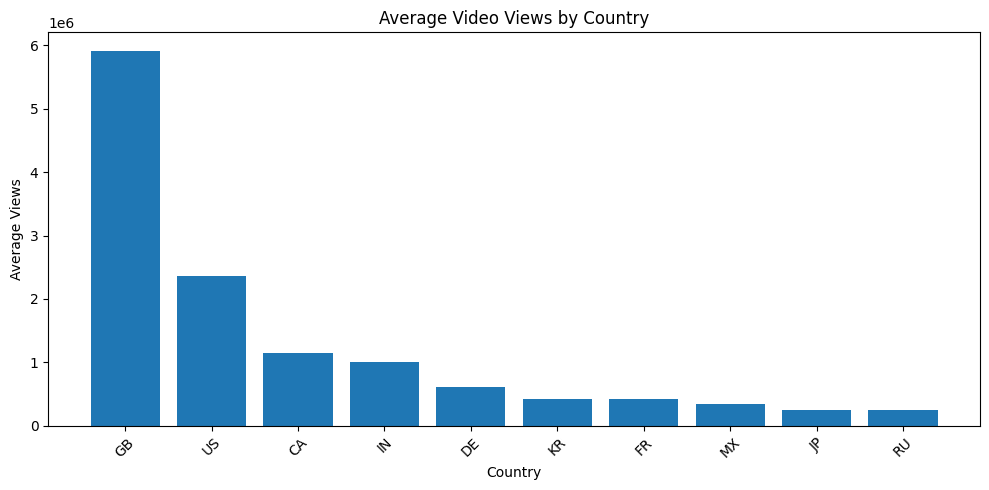

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    country_stats["country"],
    country_stats["average_views"]
)

plt.title("Average Video Views by Country")
plt.xlabel("Country")
plt.ylabel("Average Views")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
import os

print(os.listdir("/content")[:30])

['.config', 'sample_data']


In [ ]:

import os
import zipfile

# Find the uploaded ZIP file
zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
]

print("ZIP files found:", zip_files)


ZIP files found: ['archive-2.zip']


In [ ]:

import os

for f in os.listdir("/content"):
    path = os.path.join("/content", f)
    if os.path.isfile(path):
        print(f, " | Size:", os.path.getsize(path), "bytes")
    else:
        print(f, " | Folder")


.config  | Folder
archive-2.zip  | Size: 6291456 bytes
sample_data  | Folder


In [ ]:
import os
import zipfile

zip_path = "/content/archive-2.zip"

print("File exists:", os.path.exists(zip_path))
print("Valid ZIP:", zipfile.is_zipfile(zip_path))

File exists: True
Valid ZIP: False


In [ ]:
path = "/content/archive-2.zip"

with open(path, "rb") as f:
    print(f.read(20))

b'PK\x03\x04\x14\x00\x00\x00\x00\x00\xa9\xadW]\x00\x00\x00\x00\x00\x00'


In [ ]:
import os

country_codes = ["CA", "DE", "FR", "GB", "IN",
                 "JP", "KR", "MX", "RU", "US"]

for country in country_codes:
    filename = f"{country}videos.csv"
    print(filename, "—", "Available" if os.path.exists(filename) else "Missing")

CAvideos.csv — Missing
DEvideos.csv — Missing
FRvideos.csv — Missing
GBvideos.csv — Missing
INvideos.csv — Missing
JPvideos.csv — Missing
KRvideos.csv — Missing
MXvideos.csv — Missing
RUvideos.csv — Missing
USvideos.csv — Missing


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith(".zip"):
            path = os.path.join(root, file)
            print("ZIP found:", path)
            print("Size:", round(os.path.getsize(path) / (1024**2), 2), "MB")

ZIP found: /content/archive-2.zip
Size: 45.0 MB


In [ ]:
import zipfile
import os

path = "/content/archive-2.zip"

print("Valid ZIP:", zipfile.is_zipfile(path))

try:
    with zipfile.ZipFile(path, "r") as z:
        print("ZIP opened successfully!")
        print("Total files:", len(z.namelist()))
        print("First 20 files:")
        print(z.namelist()[:20])
except Exception as e:
    print("Error:", str(e))

Valid ZIP: False
Error: File is not a zip file


In [ ]:
import os

for f in os.listdir("/content"):
    if f.lower().endswith(".csv"):
        print("✅", f)

In [ ]:

import os

print(os.listdir("/content"))

['.config', 'INvideos.csv', 'RUvideos.csv', 'DEvideos.csv', 'KRvideos.csv', 'GBvideos.csv', 'MXvideos.csv', 'USvideos.csv', 'FRvideos.csv', 'CAvideos.csv', 'JPvideos.csv', 'sample_data']


In [ ]:

import os
import glob

csv_files = glob.glob("/content/**/*.csv", recursive=True)

print("Total CSV files found:", len(csv_files))
print("\nFile names:")

for file in sorted(csv_files):
    print(os.path.basename(file))

Total CSV files found: 14

File names:
CAvideos.csv
DEvideos.csv
FRvideos.csv
GBvideos.csv
INvideos.csv
JPvideos.csv
KRvideos.csv
MXvideos.csv
RUvideos.csv
USvideos.csv
california_housing_test.csv
california_housing_train.csv
mnist_test.csv
mnist_train_small.csv


In [ ]:

import pandas as pd
import glob
import os

# 1. Country codes
country_codes = ["CA", "DE", "FR", "GB", "IN", "JP", "KR", "MX", "RU", "US"]

# 2. Store each country's data
frames = []
loaded_countries = []

# 3. Load CSV files
for country in country_codes:
    matches = glob.glob(
        f"/content/**/{country}videos.csv",
        recursive=True
    )

    if not matches:
        print(f"{country}: File not found")
        continue

    file_path = matches[0]

    try:
        df = pd.read_csv(
            file_path,
            encoding="latin1",
            engine="python",
            on_bad_lines="skip"
        )

        df["country"] = country
        frames.append(df)
        loaded_countries.append(country)

        print(f"{country}: Loaded successfully — {df.shape}")

    except Exception as e:
        print(f"{country}: Error loading file — {e}")

# 4. Combine all successfully loaded files
if frames:
    all_df = pd.concat(frames, ignore_index=True)

    print("\n========== FINAL RESULT ==========")
    print("Countries loaded:", len(loaded_countries))
    print("Country codes:", loaded_countries)
    print("Combined dataset shape:", all_df.shape)
    print("\nColumn names:")
    print(all_df.columns.tolist())

else:
    print("No files were loaded. Please check the CSV file paths.")


CA: Loaded successfully — (959, 17)
DE: Loaded successfully — (919, 17)
FR: Loaded successfully — (5979, 17)
GB: Loaded successfully — (1068, 17)
IN: Loaded successfully — (4266, 17)
JP: Loaded successfully — (20523, 17)
KR: Loaded successfully — (31517, 17)
MX: Loaded successfully — (29168, 17)
RU: Loaded successfully — (17965, 17)
US: Loaded successfully — (4655, 17)

========== FINAL RESULT ==========
Countries loaded: 10
Country codes: ['CA', 'DE', 'FR', 'GB', 'IN', 'JP', 'KR', 'MX', 'RU', 'US']
Combined dataset shape: (117019, 17)

Column names:
['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country']


In [ ]:

import pandas as pd

# Convert analysis columns to numeric format
numeric_columns = ["views", "likes", "comment_count", "dislikes"]

for col in numeric_columns:
    all_df[col] = pd.to_numeric(all_df[col], errors="coerce")

# Category-wise analysis
category_stats = all_df.groupby("category_id").agg(
    total_video_records=("video_id", "count"),
    average_views=("views", "mean"),
    average_likes=("likes", "mean"),
    average_comments=("comment_count", "mean")
).reset_index()

# Sort by average views
category_stats = category_stats.sort_values(
    by="average_views",
    ascending=False
)

# Display results
display(category_stats.round(2))


,category_id,total_video_records,average_views,average_likes,average_comments
51,19,29,3419497.45,4357.17,943.52
60,28,122,1956616.37,37710.09,3431.49
48,10,243,1409835.80,43326.56,3785.32
2,10,6817,1342905.13,77446.34,8826.46
49,15,31,904520.26,32198.52,3300.19
...,...,...,...,...,...
42,to kimchi and miso,27,NaN,NaN,NaN
43,travel,5,NaN,NaN,NaN
44,videos,30,NaN,NaN,NaN
45,with Oscar-winner Graham King (âThe Departe...,7,NaN,NaN,NaN


In [ ]:

# Keep only valid numeric category IDs
all_df["category_id"] = pd.to_numeric(
    all_df["category_id"], errors="coerce"
)

# Remove rows with invalid category IDs
all_df = all_df.dropna(subset=["category_id"]).copy()

# Convert category IDs to integers
all_df["category_id"] = all_df["category_id"].astype(int)

# Calculate category-wise statistics
category_stats = all_df.groupby("category_id").agg(
    total_video_records=("video_id", "count"),
    average_views=("views", "mean"),
    average_likes=("likes", "mean"),
    average_comments=("comment_count", "mean")
).reset_index()

# Sort from highest to lowest average views
category_stats = category_stats.sort_values(
    "average_views", ascending=False
)

display(category_stats.round(2))


,category_id,total_video_records,average_views,average_likes,average_comments
2,10,7060,1345208.83,76271.97,8652.95
13,28,1522,753650.08,22292.34,3819.49
0,1,6183,429271.58,8820.41,1141.24
8,23,6450,410093.32,20947.52,2526.03
9,24,29972,408622.86,12200.83,2021.82
4,17,7470,338797.36,5973.13,727.28
5,19,515,304634.09,2782.89,531.91
6,20,3787,261110.57,10814.25,2186.51
16,43,281,202163.78,1565.89,455.74
11,26,4481,194705.25,7404.04,1009.41


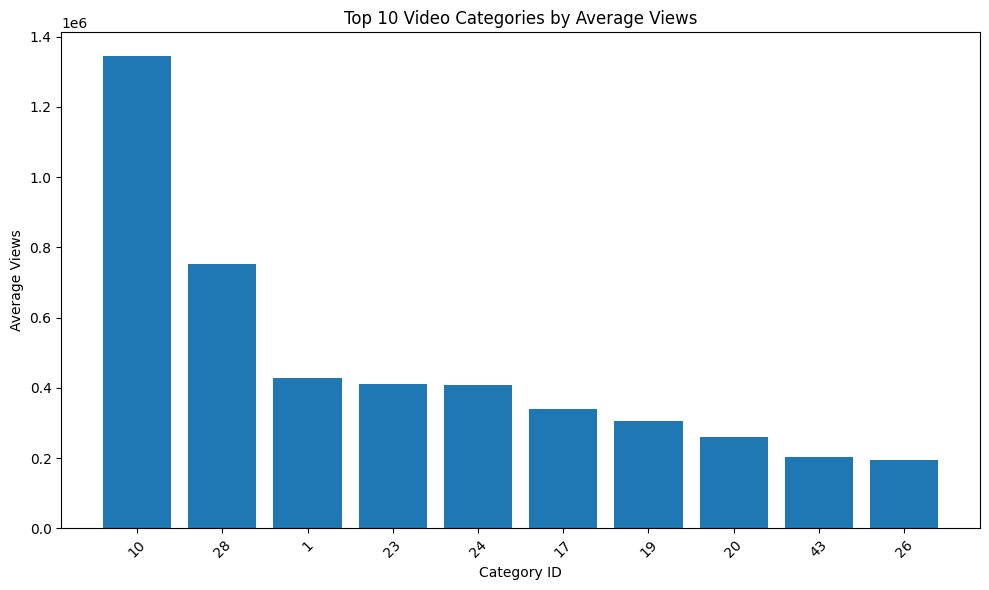

In [ ]:

import matplotlib.pyplot as plt

# Select top 10 categories by average views
top_categories = category_stats.nlargest(10, "average_views")

# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    top_categories["category_id"].astype(str),
    top_categories["average_views"]
)

plt.title("Top 10 Video Categories by Average Views")
plt.xlabel("Category ID")
plt.ylabel("Average Views")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:

!pip install vaderSentiment


In [ ]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pandas as pd

# Create sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

# Analyse video titles
def get_sentiment(title):
    if pd.isna(title):
        return "Neutral"

    score = analyzer.polarity_scores(str(title))["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

# Apply sentiment analysis
all_df["sentiment"] = all_df["title"].apply(get_sentiment)

# Count sentiment categories
sentiment_counts = all_df["sentiment"].value_counts()

print("Sentiment Analysis Results:")
display(sentiment_counts.to_frame(name="Number of Videos"))


Sentiment Analysis Results:


,Number of Videos
sentiment,
Neutral,98366
Positive,7399
Negative,5976


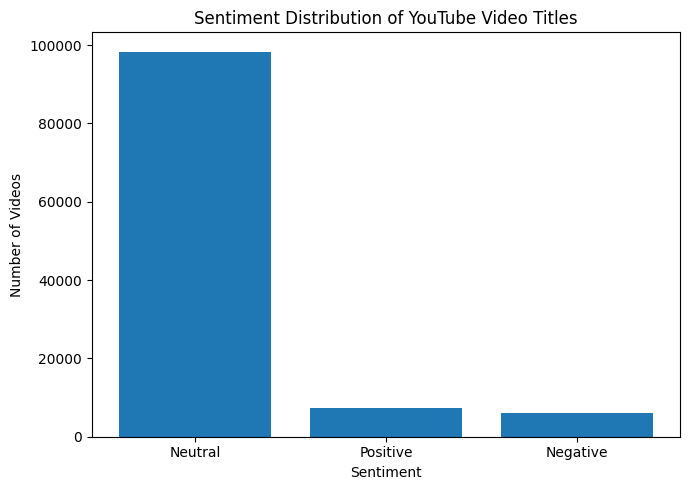

In [ ]:

import matplotlib.pyplot as plt

sentiment_counts = all_df["sentiment"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)

plt.title("Sentiment Distribution of YouTube Video Titles")
plt.xlabel("Sentiment")
plt.ylabel("Number of Videos")
plt.tight_layout()
plt.show()


In [ ]:

import sqlite3

# Create an in-memory SQL database
conn = sqlite3.connect(":memory:")

# Save dataset into a SQL table
all_df.to_sql(
    "youtube_trending",
    conn,
    if_exists="replace",
    index=False
)

print("SQL database created successfully!")
print("Table name: youtube_trending")


SQL database created successfully!
Table name: youtube_trending


In [ ]:

query = """
SELECT
    title,
    channel_title,
    country,
    views,
    likes
FROM youtube_trending
ORDER BY views DESC
LIMIT 10;
"""

top_videos = pd.read_sql_query(query, conn)

display(top_videos)


,title,channel_title,country,views,likes
0,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,KR,113876217.0,2811223.0
1,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,MX,100912384.0,2656698.0
2,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,FR,100911567.0,2656682.0
3,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,KR,100911567.0,2656686.0
4,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,KR,87450245.0,2584675.0
5,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,IN,87449453.0,2584674.0
6,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,KR,87430865.0,5150839.0
7,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,IN,84281319.0,2555411.0
8,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,KR,84281319.0,2555414.0
9,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,KR,80738011.0,5053338.0


In [ ]:

query = """
SELECT
    country,
    COUNT(*) AS total_video_records,
    ROUND(AVG(views), 2) AS average_views,
    ROUND(AVG(likes), 2) AS average_likes
FROM youtube_trending
GROUP BY country
ORDER BY average_views DESC;
"""

country_performance = pd.read_sql_query(query, conn)

display(country_performance)


,country,total_video_records,average_views,average_likes
0,US,1193,1066552.65,22836.98
1,IN,4266,830884.65,19839.84
2,GB,289,519640.64,15634.04
3,CA,360,461078.97,14213.48
4,KR,31517,433197.97,12207.63
5,FR,5979,368591.08,16940.78
6,MX,29168,328789.06,15501.22
7,JP,20523,262021.47,8059.59
8,RU,17965,208332.50,11437.94
9,DE,481,191208.98,3850.69


In [ ]:

query = """
SELECT
    title,
    channel_title,
    country,
    views,
    likes
FROM youtube_trending
ORDER BY likes DESC
LIMIT 10;
"""

top_liked_videos = pd.read_sql_query(query, conn)

display(top_liked_videos)


,title,channel_title,country,views,likes
0,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,KR,87430865.0,5150839.0
1,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,KR,80738011.0,5053338.0
2,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,KR,73463137.0,4924056.0
3,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,KR,73463137.0,4924056.0
4,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,KR,65396157.0,4750254.0
5,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,KR,65396157.0,4750254.0
6,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,JP,62796390.0,4470923.0
7,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,JP,62796390.0,4470923.0
8,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,JP,62796390.0,4470923.0
9,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,JP,62796390.0,4470923.0


In [ ]:

query = """
SELECT
    video_id,
    title,
    channel_title,
    MAX(views) AS highest_views,
    MAX(likes) AS highest_likes
FROM youtube_trending
GROUP BY video_id, title, channel_title
ORDER BY highest_likes DESC
LIMIT 10;
"""

top_unique_liked_videos = pd.read_sql_query(query, conn)

display(top_unique_liked_videos)


,video_id,title,channel_title,highest_views,highest_likes
0,7C2z4GqqS5E,BTS (ë°©íìë ë¨) 'FAKE LOVE' Official MV,ibighit,87430865.0,5150839.0
1,FlsCjmMhFmw,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,113876217.0,2811223.0
2,kTlv5_Bs8aw,BTS (ë°©íìë ë¨) 'MIC Drop (Steve Aoki Re...,ibighit,30583293.0,2611254.0
3,6ZfuNTqbHE8,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,87450245.0,2584675.0
4,p8npDG2ulKQ,BTS (ë°©íìë ë¨) LOVE YOURSELF è½ Tear '...,ibighit,22612931.0,2533784.0
5,VYOjWnS4cMY,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,73432600.0,2478908.0
6,OK3GJ0WIQ8s,j-hope 'Daydream (ë°±ì¼ëª½)' MV,ibighit,10695328.0,2050610.0
7,ffxKSjUwKdU,Ariana Grande - No Tears Left To Cry,ArianaGrandeVevo,32331284.0,1890564.0
8,kX0vO4vlJuU,BTS (ë°©íìë ë¨) 'Euphoria : Theme of LOV...,ibighit,10208424.0,1795555.0
9,TyHvyGVs42U,"Luis Fonsi, Demi Lovato - Ãchame La Culpa",LuisFonsiVEVO,47078714.0,1763400.0


In [ ]:

# Convert trending_date into datetime format
all_df["trending_date_parsed"] = pd.to_datetime(
    all_df["trending_date"],
    format="%y.%d.%m",
    errors="coerce"
)

# Calculate how many days each video appeared in the dataset
trending_duration = all_df.groupby(
    ["video_id", "title", "country"]
).agg(
    first_trending_date=("trending_date_parsed", "min"),
    last_trending_date=("trending_date_parsed", "max"),
    trending_records=("trending_date_parsed", "count")
).reset_index()

# Calculate duration in days
trending_duration["trending_days"] = (
    trending_duration["last_trending_date"]
    - trending_duration["first_trending_date"]
).dt.days + 1

# Show videos with longest trending duration
trending_duration = trending_duration.sort_values(
    "trending_days", ascending=False
)

display(trending_duration.head(10))


,video_id,title,country,first_trending_date,last_trending_date,trending_records,trending_days
114,#NAME?,"Bachatas 2018 Romanticas - Prince Royce, Shaki...",MX,2018-01-16,2018-03-06,3,50
67999,tE5C3O71Xqo,"SpaceX Iridium 4 Launch from Alhambra, CA",US,2017-12-23,2018-01-04,13,13
61234,nUv22OHdjQU,[HD] Christina Aguilera - Whitney Houston TRIB...,GB,2017-11-21,2017-12-03,13,13
10476,7keZTcdouoY,President Trump Signs Tax Bill,US,2017-12-23,2018-01-03,12,12
44608,_akwfRuL4os,Highlights of the EA predatory behavior announ...,GB,2017-11-23,2017-12-04,12,12
70349,vFK7oWLWapc,Justice League Bad,GB,2017-11-23,2017-12-04,12,12
38287,VEoOuF_cN0Q,Cal Jam 17 - Good Times!,GB,2017-11-15,2017-11-25,11,11
71877,wbSwFU6tY1c,Falcon Heavy Test Flight,US,2018-02-07,2018-02-16,10,10
38044,V3EYjVPRClU,Sia - Santa's Coming For Us,GB,2017-11-23,2017-12-02,10,10
59744,mCcN8NVAB8A,And now - CBS This Mornings awkward sex talk,GB,2017-11-24,2017-12-03,10,10


In [ ]:

# Keep valid video IDs and videos with at least 3 trending records
clean_duration = trending_duration[
    trending_duration["video_id"].notna()
    & (trending_duration["video_id"] != "#NAME?")
    & (trending_duration["trending_records"] >= 3)
].copy()

# Sort by number of recorded trending appearances
clean_duration = clean_duration.sort_values(
    by=["trending_records", "trending_days"],
    ascending=False
)

display(clean_duration.head(10))


,video_id,title,country,first_trending_date,last_trending_date,trending_records,trending_days
67999,tE5C3O71Xqo,"SpaceX Iridium 4 Launch from Alhambra, CA",US,2017-12-23,2018-01-04,13,13
61234,nUv22OHdjQU,[HD] Christina Aguilera - Whitney Houston TRIB...,GB,2017-11-21,2017-12-03,13,13
10476,7keZTcdouoY,President Trump Signs Tax Bill,US,2017-12-23,2018-01-03,12,12
44608,_akwfRuL4os,Highlights of the EA predatory behavior announ...,GB,2017-11-23,2017-12-04,12,12
70349,vFK7oWLWapc,Justice League Bad,GB,2017-11-23,2017-12-04,12,12
38287,VEoOuF_cN0Q,Cal Jam 17 - Good Times!,GB,2017-11-15,2017-11-25,11,11
71877,wbSwFU6tY1c,Falcon Heavy Test Flight,US,2018-02-07,2018-02-16,10,10
38044,V3EYjVPRClU,Sia - Santa's Coming For Us,GB,2017-11-23,2017-12-02,10,10
59744,mCcN8NVAB8A,And now - CBS This Mornings awkward sex talk,GB,2017-11-24,2017-12-03,10,10
49829,e1bEWoblGZA,unboxing video,US,2018-02-14,2018-02-22,9,9


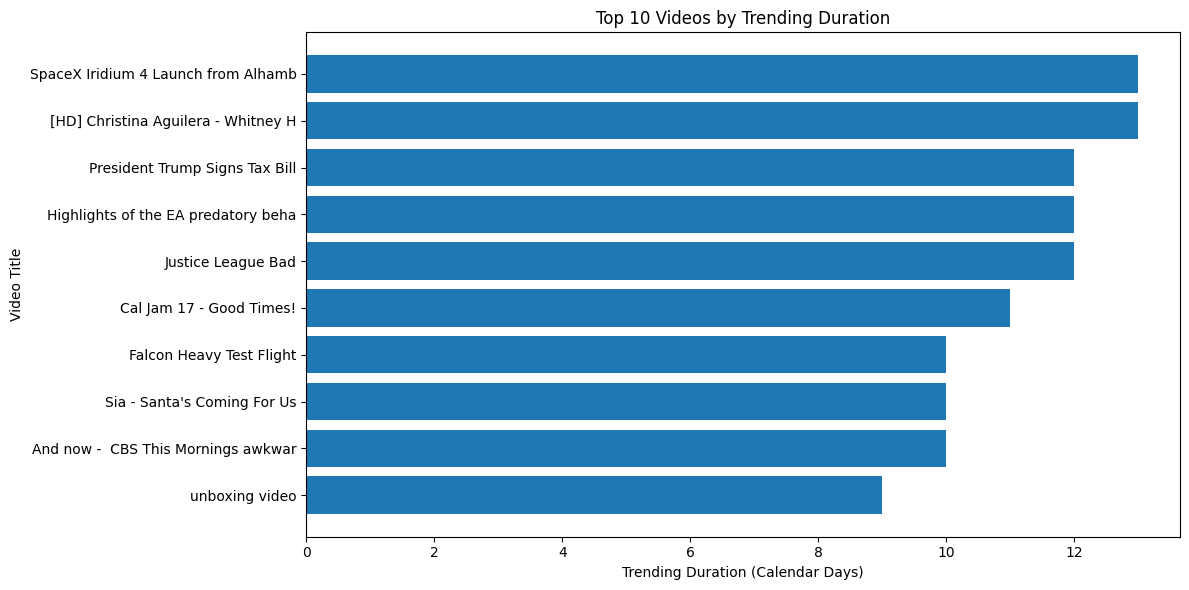

In [ ]:

import matplotlib.pyplot as plt

# Select top 10 videos by trending records
top_duration = clean_duration.head(10).copy()

# Shorten long titles for readability
top_duration["short_title"] = (
    top_duration["title"].str.slice(0, 35)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_duration["short_title"],
    top_duration["trending_days"]
)

plt.title("Top 10 Videos by Trending Duration")
plt.xlabel("Trending Duration (Calendar Days)")
plt.ylabel("Video Title")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:

# Export country-wise performance
country_performance.to_csv(
    "country_performance.csv",
    index=False
)

# Export category analysis
category_stats.to_csv(
    "category_analysis.csv",
    index=False
)

# Export sentiment results
sentiment_counts = all_df["sentiment"].value_counts().reset_index()
sentiment_counts.columns = ["sentiment", "number_of_videos"]

sentiment_counts.to_csv(
    "sentiment_analysis.csv",
    index=False
)

# Export trending duration analysis
clean_duration.to_csv(
    "trending_duration.csv",
    index=False
)

print("All 4 analysis CSV files exported successfully!")


All 4 analysis CSV files exported successfully!


In [ ]:

from google.colab import files

files.download("country_performance.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download("category_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download("sentiment_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download("trending_duration.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>